# Entanglement Swapping Chain (a toy quantum repeater)

The first notebook (`entanglement_swapping.ipynb`) swapped entanglement **once**: two Bell pairs, one Bell
measurement, and the two end qubits (q0, q3) became entangled.

Here we make the chain longer. With **n swaps** we use **n + 1 Bell pairs** (2n + 2 qubits) and do a Bell
measurement on every pair of neighbouring inner qubits. The two qubits at the very ends of the chain
become entangled, even though they are far apart and never interacted:

```
1 swap :  (q0 q1)(q2 q3)                          ends: q0 ... q3
2 swaps:  (q0 q1)(q2 q3)(q4 q5)                   ends: q0 ... q5
3 swaps:  (q0 q1)(q2 q3)(q4 q5)(q6 q7)            ends: q0 ... q7
              \___/   \___/   \___/
            Bell measurements on the inner neighbours
```

This is how a **quantum repeater** would carry entanglement over a long distance: build short links, then
glue them together with swaps.

**Question this notebook answers:** how quickly does the end-to-end entanglement fade as the chain gets
longer, and how many swaps can the hardware do before it is lost (fidelity drops to 0.5)?

## What changes compared with one swap

**1. All Bell measurements can happen at the same time.** The order of the swaps does not matter, so the
circuit does every Bell measurement in parallel. The circuit depth stays the same for any chain length;
what grows is the **number of qubits and gates** that can make an error.

**2. The correction combines all the measurement results.** Each Bell measurement k gives two bits
(m1_k, m2_k). The Pauli corrections from all the swaps stack up, and only their **parity** (even or odd)
matters:

```
M1 = m1_1 XOR m1_2 XOR ... XOR m1_n     (decides the Z correction)
M2 = m2_1 XOR m2_2 XOR ... XOR m2_n     (decides the X correction)
```

The pair (M1, M2) tells us which of the 4 Bell states the end qubits are in, using the same table as
before (00 = Φ+, 01 = Ψ+, 10 = Φ-, 11 = Ψ-). So the analysis from the first notebook is reused as is:
we just replace (m1, m2) by (M1, M2).

**3. One wrong bit spoils the shot.** If any one of the 2n Bell-measurement bits is read wrongly, the
parity flips and the shot gets the wrong correction. That is the main reason fidelity drops with length.

## What we expect
A simple model: describe each shot's quality by a "visibility" v, where

```
F = 1/4 + (3/4) * v        v = 1: perfect Bell state      v = 0: pure noise (F = 0.25)
```

If every extra swap multiplies v by the same factor r (< 1), then

```
v(n) = a * r^n      so      F(n) = 1/4 + (3/4) * a * r^n
```

F falls towards 0.25 exponentially. Entanglement is proven only while F > 0.5, i.e. while v > 1/3.
The notebook fits a and r to the hardware data and predicts the longest chain that stays entangled.

## 0. Setup
Uses the same `.env` as the first notebook.

In [1]:
import json
import os
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
import qiskit_ibm_runtime
from dotenv import load_dotenv
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

print("qiskit            ", qiskit.__version__)
print("qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit             2.5.2
qiskit-ibm-runtime 0.50.0


In [2]:
load_dotenv()

N_SWAPS = [1, 2, 3, 4, 6, 8, 10]   # chain lengths to test (qubits = 2 * n + 2, so 4 ... 22)
SHOTS = 4000                       # per circuit
INCLUDE_CONTROLS = True            # also run each chain without its Bell measurements
SIM_MAX_QUBITS = 14                # ideal local check only up to this size (memory grows as 2^qubits)
BACKEND_NAME = os.getenv("IBM_BACKEND") or None

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

BASES = ["XX", "YY", "ZZ"]
BELL_LABELS = {"00": "Φ+", "01": "Ψ+", "10": "Φ-", "11": "Ψ-"}  # key = M1 M2

n_circuits = len(N_SWAPS) * len(BASES) * (2 if INCLUDE_CONTROLS else 1)
print(f"{n_circuits} circuits, {n_circuits * SHOTS:,} shots in total, largest chain = {2 * max(N_SWAPS) + 2} qubits")

42 circuits, 168,000 shots in total, largest chain = 22 qubits


## 1. Build the chain circuits

Register layout (generalises the first notebook):

- `bsm[2k]` = m1 of swap k (qubit 2k+1), `bsm[2k+1]` = m2 of swap k (qubit 2k+2), for k = 0 ... n-1
- `out[0]` = q0 (left end), `out[1]` = last qubit (right end)

With `n_swaps = 1` this is exactly the circuit from the first notebook.

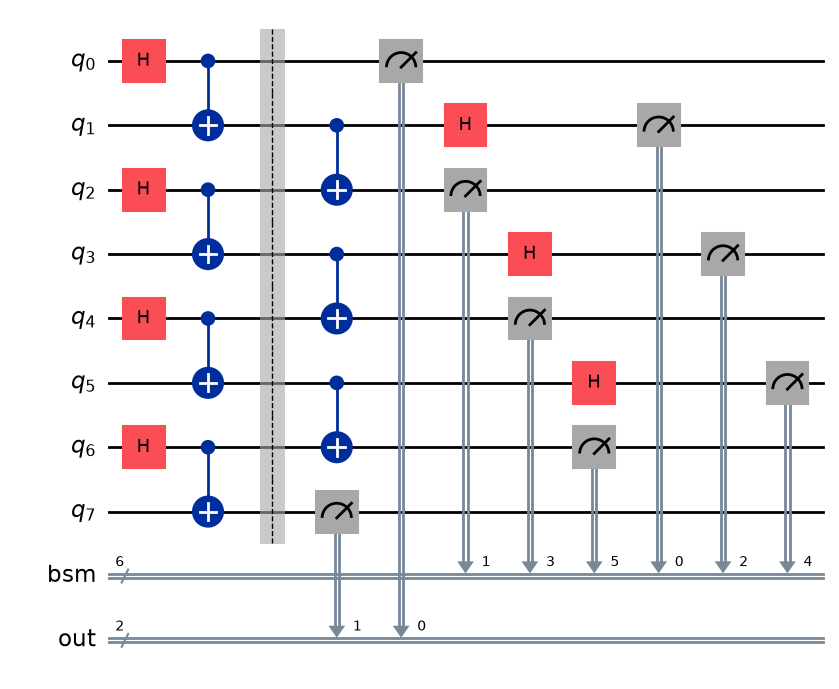

In [3]:
def add_basis_measurement(qc, basis, qubit):
    # Rotate so that a Z-measurement measures the requested Pauli.
    if basis == "X":
        qc.h(qubit)
    elif basis == "Y":
        qc.sdg(qubit)
        qc.h(qubit)


def build_chain_circuit(n_swaps, basis, bell_measurement=True, wait_ns=0):
    n_qubits = 2 * n_swaps + 2
    last = n_qubits - 1
    q = QuantumRegister(n_qubits, "q")
    bsm = ClassicalRegister(2 * n_swaps, "bsm")
    out = ClassicalRegister(2, "out")
    tag = "chain" if bell_measurement else "control"
    qc = QuantumCircuit(q, bsm, out, name=f"{tag}{n_swaps}_{basis}" + (f"_w{wait_ns}" if wait_ns else ""))

    # n + 1 Bell pairs: (q0 q1), (q2 q3), ...
    for a in range(0, n_qubits, 2):
        qc.h(a)
        qc.cx(a, a + 1)
    qc.barrier()

    # Optional: the Bell pairs wait in "memory" before the swaps (used in Part 3)
    if wait_ns:
        qc.delay(wait_ns, q, unit="ns")
        qc.barrier()

    # Bell measurements on every inner neighbour pair (q1 q2), (q3 q4), ... all in parallel
    for k in range(n_swaps):
        left, right = 2 * k + 1, 2 * k + 2
        if bell_measurement:
            qc.cx(left, right)
            qc.h(left)
        qc.measure(left, bsm[2 * k])       # m1 of swap k
        qc.measure(right, bsm[2 * k + 1])  # m2 of swap k

    # Measure the two ends in the requested basis
    add_basis_measurement(qc, basis[0], 0)
    add_basis_measurement(qc, basis[1], last)
    qc.measure(0, out[0])
    qc.measure(last, out[1])
    return qc


circuits, labels = [], []   # labels[i] = (kind, n_swaps, basis)
for n in N_SWAPS:
    kinds = ["chain", "control"] if INCLUDE_CONTROLS else ["chain"]
    for kind in kinds:
        for b in BASES:
            circuits.append(build_chain_circuit(n, b, bell_measurement=(kind == "chain")))
            labels.append((kind, n, b))

build_chain_circuit(3, "ZZ").draw("mpl", fold=-1)

## 2. Analysis helpers

Same fidelity formula and correction rules as the first notebook; the only new step is turning the
2n Bell-measurement bits of a shot into the two parities (M1, M2).

In [4]:
CORRECTION_SIGN = {  # basis -> function(M1, M2) -> ±1
    "XX": lambda m1, m2: (-1) ** m1,
    "YY": lambda m1, m2: (-1) ** (m1 + m2),
    "ZZ": lambda m1, m2: (-1) ** m2,
}
BELL_CORRELATORS = {
    "Φ+": {"XX": 1, "YY": -1, "ZZ": 1},
    "Φ-": {"XX": -1, "YY": 1, "ZZ": 1},
    "Ψ+": {"XX": 1, "YY": 1, "ZZ": -1},
    "Ψ-": {"XX": -1, "YY": -1, "ZZ": -1},
}


def joint_counts(pub_result):
    # {"M1M2 ab": count}: M1/M2 = parity of all m1 / m2 bits, a = left end, b = right end
    bsm = pub_result.data.bsm.get_bitstrings()
    out = pub_result.data.out.get_bitstrings()
    counts = defaultdict(int)
    for s_bsm, s_out in zip(bsm, out):
        bits = s_bsm[::-1]                     # little-endian -> bits[i] = bsm[i]
        M1 = bits[0::2].count("1") % 2
        M2 = bits[1::2].count("1") % 2
        counts[f"{M1}{M2} {s_out[::-1]}"] += 1
    return dict(counts)


def _correlator(samples):
    # samples: list of (±1, count) -> (mean, standard error)
    n = sum(c for _, c in samples)
    if n == 0:
        return float("nan"), float("nan")
    mean = sum(v * c for v, c in samples) / n
    return mean, np.sqrt(max(1 - mean**2, 0) / n)


def _fidelity(corr, target):
    f = (1 + sum(target[b] * corr[b][0] for b in BASES)) / 4
    err = np.sqrt(sum(corr[b][1] ** 2 for b in BASES)) / 4
    return f, err


def analyze(counts_by_basis):
    # counts_by_basis: {"XX": joint_counts, "YY": ..., "ZZ": ...}
    per_outcome = {k: {} for k in BELL_LABELS}
    corrected, uncorrected = {}, {}
    for basis in BASES:
        groups = {k: [] for k in BELL_LABELS}
        all_corr, all_raw = [], []
        for key, n in counts_by_basis[basis].items():
            mm, ab = key.split()
            parity = 1 if ab[0] == ab[1] else -1
            groups[mm].append((parity, n))
            all_raw.append((parity, n))
            all_corr.append((CORRECTION_SIGN[basis](int(mm[0]), int(mm[1])) * parity, n))
        for mm in BELL_LABELS:
            per_outcome[mm][basis] = _correlator(groups[mm])
        corrected[basis] = _correlator(all_corr)
        uncorrected[basis] = _correlator(all_raw)

    summary = {}
    for mm, label in BELL_LABELS.items():
        f, e = _fidelity(per_outcome[mm], BELL_CORRELATORS[label])
        summary[f"{label} ({mm})"] = {"F": f, "err": e}
    phi_plus = BELL_CORRELATORS["Φ+"]
    summary["All, corrected"] = dict(zip(("F", "err"), _fidelity(corrected, phi_plus)))
    summary["All, uncorrected"] = dict(zip(("F", "err"), _fidelity(uncorrected, phi_plus)))
    summary["_correlators_corrected"] = {b: corrected[b][0] for b in BASES}
    return summary


def analyze_all(result, run_labels):
    # result + matching labels -> {"chain": {n: summary}, "control": {n: summary}}, raw counts alike
    grouped = defaultdict(lambda: defaultdict(dict))
    for pub_result, (kind, n, b) in zip(result, run_labels, strict=True):
        grouped[kind][n][b] = joint_counts(pub_result)
    summaries = {kind: {n: analyze(c) for n, c in by_n.items()} for kind, by_n in grouped.items()}
    counts = {kind: {n: dict(c) for n, c in by_n.items()} for kind, by_n in grouped.items()}
    return summaries, counts


def print_table(title, summaries):
    print(title)
    print(f"  {'swaps':>5} {'qubits':>6}   {'F chain':>15}   {'F control':>9}   {'F uncorrected':>13}   per-outcome F (Φ+ Ψ+ Φ- Ψ-)")
    for n in sorted(summaries["chain"]):
        s = summaries["chain"][n]
        fc = s["All, corrected"]
        ctrl = summaries.get("control", {}).get(n)
        ctrl_txt = f"{ctrl['All, corrected']['F']:.3f}" if ctrl else "-"
        outcomes = " ".join(f"{s[k]['F']:.2f}" for k in s if "(" in k)
        verdict = "entangled" if fc["F"] - 2 * fc["err"] > 0.5 else "not proven"
        print(f"  {n:>5} {2 * n + 2:>6}   {fc['F']:.3f} ± {fc['err']:.3f}   {ctrl_txt:>9}   "
              f"{s['All, uncorrected']['F']:>13.3f}   {outcomes}   {verdict}")

In [5]:
COLOR_CHAIN = "#2a78d6"    # series 1
COLOR_CONTROL = "#eb6834"  # series 2
INK = "#52514e"


def fit_decay(summaries):
    # Fit v(n) = a * r^n with v = (4F - 1) / 3, using points where v is clearly above 0
    ns = sorted(summaries["chain"])
    n = np.array(ns, dtype=float)
    F = np.array([summaries["chain"][k]["All, corrected"]["F"] for k in ns])
    v = (4 * F - 1) / 3
    ok = v > 0.05
    if ok.sum() < 2:
        return None
    slope, intercept = np.polyfit(n[ok], np.log(v[ok]), 1)
    a, r = float(np.exp(intercept)), float(np.exp(slope))
    n_max = np.log(1 / (3 * a)) / np.log(r) if r < 1 else float("inf")  # where v = 1/3, i.e. F = 0.5
    return {"a": a, "r": r, "n_max": float(n_max)}


def plot_chain(summaries, title, fit=None):
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ns = sorted(summaries["chain"])
    n = np.array(ns)
    F = [summaries["chain"][k]["All, corrected"]["F"] for k in ns]
    E = [summaries["chain"][k]["All, corrected"]["err"] for k in ns]
    ax.errorbar(n, F, yerr=E, color=COLOR_CHAIN, marker="o", markersize=7, linewidth=2,
                capsize=3, label="Swap chain (corrected)")
    if "control" in summaries:
        Fc = [summaries["control"][k]["All, corrected"]["F"] for k in ns]
        Ec = [summaries["control"][k]["All, corrected"]["err"] for k in ns]
        ax.errorbar(n, Fc, yerr=Ec, color=COLOR_CONTROL, marker="s", markersize=7, linewidth=2,
                    capsize=3, label="Control (no Bell measurements)")
    if fit:
        xs = np.linspace(min(ns), max(ns), 200)
        ax.plot(xs, 0.25 + 0.75 * fit["a"] * fit["r"] ** xs, color=COLOR_CHAIN, linestyle="--",
                linewidth=1, alpha=0.7, label=f"fit: F = 1/4 + 3/4 · {fit['a']:.2f} · {fit['r']:.3f}^n")
    ax.axhline(0.5, color=INK, linestyle="--", linewidth=1)
    ax.text(min(ns), 0.515, "entanglement threshold F = 0.5", ha="left", va="bottom", color=INK, fontsize=9)
    ax.axhline(0.25, color=INK, linestyle=":", linewidth=1)
    ax.text(min(ns), 0.265, "pure noise F = 0.25", ha="left", va="bottom", color=INK, fontsize=9)
    ax.set_xticks(ns, [f"{k}\n({2 * k + 2} q)" for k in ns])
    ax.set_xlabel("number of swaps (qubits used)")
    ax.set_ylabel("Fidelity of the two end qubits")
    ax.set_ylim(0, 1.05)
    ax.set_title(title, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2)
    fig.tight_layout()
    return fig

## Part 1: Ideal local simulation

Without noise every chain length should give F = 1, the uncorrected value should be about 0.25 and the
controls should be about 0.25. This checks the circuits and the parity rule before using hardware time.

Only chains up to `SIM_MAX_QUBITS` qubits are simulated: a statevector simulation needs memory that
doubles with every extra qubit (22 qubits would need several GB). The parity rule is the same for every
length, so checking the shorter chains is enough.

IDEAL SIMULATION
  swaps qubits           F chain   F control   F uncorrected   per-outcome F (Φ+ Ψ+ Φ- Ψ-)
      1      4   1.000 ± 0.000       0.245           0.259   1.00 1.00 1.00 1.00   entangled
      2      6   1.000 ± 0.000       0.258           0.247   1.00 1.00 1.00 1.00   entangled
      3      8   1.000 ± 0.000       0.248           0.251   1.00 1.00 1.00 1.00   entangled
      4     10   1.000 ± 0.000       0.257           0.248   1.00 1.00 1.00 1.00   entangled
      6     14   1.000 ± 0.000       0.253           0.245   1.00 1.00 1.00 1.00   entangled


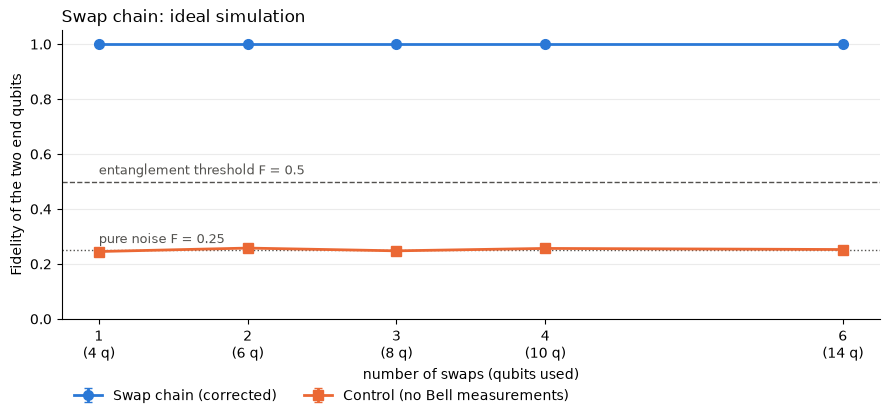

In [6]:
sim_idx = [i for i, qc in enumerate(circuits) if qc.num_qubits <= SIM_MAX_QUBITS]
sim_result = StatevectorSampler(seed=1234).run([circuits[i] for i in sim_idx], shots=SHOTS).result()
sim_summaries, sim_counts = analyze_all(sim_result, [labels[i] for i in sim_idx])
print_table("IDEAL SIMULATION", sim_summaries)
plot_chain(sim_summaries, "Swap chain: ideal simulation");

## Part 2: Run on IBM Quantum hardware

### 2a. Connect

In [7]:
token = os.getenv("QISKIT_IBM_TOKEN")
if not token:
    raise RuntimeError("QISKIT_IBM_TOKEN not found — create a .env file (see .env.example)")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=token,
    instance=os.getenv("QISKIT_IBM_INSTANCE") or None,
)
n_needed = 2 * max(N_SWAPS) + 2
if BACKEND_NAME:
    backend = service.backend(BACKEND_NAME)
else:
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=n_needed)

print(f"Backend: {backend.name}  ({backend.num_qubits} qubits)  pending jobs: {backend.status().pending_jobs}")

qiskit_runtime_service._discover_account:WARNING:2026-10-15 23:37:49,406: Loading account with the given token. A saved account will not be used.


Backend: ibm_marrakesh  (156 qubits)  pending jobs: 0


### 2b. Choose one line of physical qubits for every chain

The chain only needs gates between neighbours, so it fits on a **line** of qubits on the chip. We let the
transpiler pick the best line for the **longest** chain, then every shorter chain uses the beginning of that
same line. This way a longer chain differs from a shorter one only by the extra qubits added at the end.

The check below confirms that no SWAP gates were added: a chain with n swaps should have exactly
(n + 1) + n two-qubit gates (one per Bell pair and one per Bell measurement).

In [8]:
longest = build_chain_circuit(max(N_SWAPS), "ZZ")
pm_search = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=1234)
LINE = pm_search.run(longest).layout.initial_index_layout(filter_ancillas=True)
print("Physical qubit line:", LINE)

isa_circuits = []
for qc, (kind, n, b) in zip(circuits, labels):
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3,
                                      initial_layout=LINE[:qc.num_qubits], seed_transpiler=1234)
    isa_circuits.append(pm.run(qc))

for isa, (kind, n, b) in zip(isa_circuits, labels):
    if kind != "chain" or b != "ZZ":
        continue
    n_2q = sum(1 for inst in isa.data if inst.operation.num_qubits == 2)
    expected = 2 * n + 1
    flag = "ok" if n_2q == expected else f"WARNING: {n_2q - expected} extra 2q gates (routing SWAPs)"
    print(f"{n:>2} swaps  qubits {LINE[:2 * n + 2]}   2q gates {n_2q}   depth {isa.depth()}   {flag}")

Physical qubit line: [92, 91, 98, 111, 110, 109, 108, 107, 106, 105, 117, 125, 124, 123, 136, 143, 144, 145, 146, 147, 148, 149]
 1 swaps  qubits [92, 91, 98, 111]   2q gates 3   depth 14   ok
 2 swaps  qubits [92, 91, 98, 111, 110, 109]   2q gates 5   depth 14   ok
 3 swaps  qubits [92, 91, 98, 111, 110, 109, 108, 107]   2q gates 7   depth 14   ok
 4 swaps  qubits [92, 91, 98, 111, 110, 109, 108, 107, 106, 105]   2q gates 9   depth 14   ok
 6 swaps  qubits [92, 91, 98, 111, 110, 109, 108, 107, 106, 105, 117, 125, 124, 123]   2q gates 13   depth 14   ok
 8 swaps  qubits [92, 91, 98, 111, 110, 109, 108, 107, 106, 105, 117, 125, 124, 123, 136, 143, 144, 145]   2q gates 17   depth 14   ok
10 swaps  qubits [92, 91, 98, 111, 110, 109, 108, 107, 106, 105, 117, 125, 124, 123, 136, 143, 144, 145, 146, 147, 148, 149]   2q gates 21   depth 14   ok


### 2c. Submit
All circuits go in **one** job. The job ID is saved to `results/` straight away.

In [9]:
sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=SHOTS)
JOB_ID = job.job_id()

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
(RESULTS_DIR / f"{run_stamp}_{backend.name}_chain_job.txt").write_text(JOB_ID, encoding="utf-8")
print("Submitted job", JOB_ID, "on", backend.name)
print("Track it at https://quantum.cloud.ibm.com/workloads")

C:\Users\LOQ\AppData\Local\Temp\ipykernel_16172\1788988815.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Submitted job db8rgg1eukqs73ar68m0 on ibm_marrakesh
Track it at https://quantum.cloud.ibm.com/workloads


### 2d. (Optional) Retrieve a previous job
Run sections 0, 1, 2 and 2a first (with the same `N_SWAPS` and `INCLUDE_CONTROLS` as the original job,
because `labels` must match), then this cell instead of 2b and 2c.

In [10]:
# JOB_ID = "paste-job-id-here"
# job = service.job(JOB_ID)
# backend = job.backend()
# LINE = None   # not stored in the job; check the matching *_chain_results.json if needed
# run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

### 2e. Results

HARDWARE (ibm_marrakesh)
  swaps qubits           F chain   F control   F uncorrected   per-outcome F (Φ+ Ψ+ Φ- Ψ-)
      1      4   0.930 ± 0.003       0.261           0.249   0.91 0.93 0.93 0.95   entangled
      2      6   0.823 ± 0.004       0.253           0.231   0.82 0.82 0.83 0.82   entangled
      3      8   0.805 ± 0.005       0.252           0.255   0.79 0.81 0.82 0.80   entangled
      4     10   0.763 ± 0.005       0.246           0.252   0.77 0.75 0.77 0.77   entangled
      6     14   0.662 ± 0.006       0.262           0.249   0.66 0.65 0.67 0.67   entangled
      8     18   0.572 ± 0.006       0.241           0.251   0.57 0.56 0.59 0.56   entangled
     10     22   0.540 ± 0.006       0.254           0.244   0.53 0.54 0.57 0.53   entangled

Fit: each extra swap keeps 90.9% of the visibility (a = 0.973).
Predicted longest chain that stays entangled (F > 0.5): about 11.2 swaps.


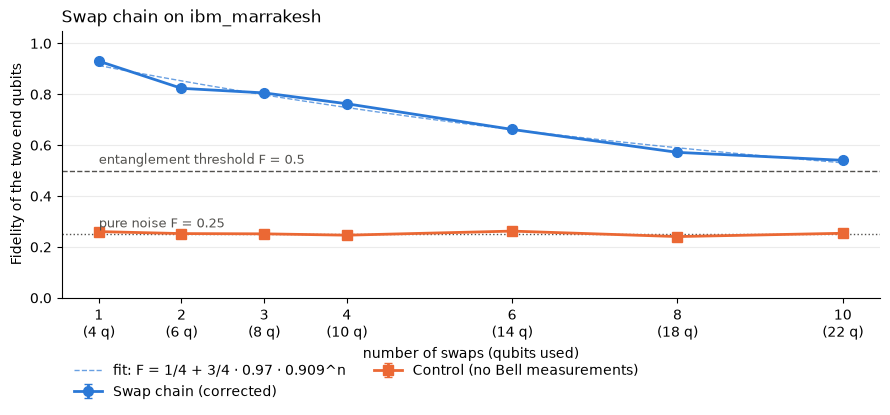

In [11]:
hw_result = job.result()
hw_summaries, hw_counts = analyze_all(hw_result, labels)
print_table(f"HARDWARE ({backend.name})", hw_summaries)

fit = fit_decay(hw_summaries)
if fit:
    print(f"\nFit: each extra swap keeps {fit['r']:.1%} of the visibility (a = {fit['a']:.3f}).")
    print(f"Predicted longest chain that stays entangled (F > 0.5): about {fit['n_max']:.1f} swaps.")

fig = plot_chain(hw_summaries, f"Swap chain on {backend.name}", fit)
fig.savefig(RESULTS_DIR / f"{run_stamp}_{backend.name}_chain_fidelity.png", dpi=150)

In [12]:
record = {
    "experiment": "entanglement_swapping_chain",
    "timestamp_utc": run_stamp,
    "backend": backend.name,
    "job_id": JOB_ID,
    "shots_per_circuit": SHOTS,
    "n_swaps": N_SWAPS,
    "physical_qubit_line": LINE,
    "qiskit": qiskit.__version__,
    "qiskit_ibm_runtime": qiskit_ibm_runtime.__version__,
    "fit": fit,
    # counts keyed "M1M2 ab" (parities of all Bell-measurement bits, then the two end qubits)
    "counts": {kind: {str(n): c for n, c in by_n.items()} for kind, by_n in hw_counts.items()},
    "summary": {kind: {str(n): s for n, s in by_n.items()} for kind, by_n in hw_summaries.items()},
}
path = RESULTS_DIR / f"{run_stamp}_{backend.name}_chain_results.json"
path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", path)

print("\nLog lines for CLAUDE.md:")
for n in N_SWAPS:
    s = hw_summaries["chain"][n]["All, corrected"]
    ctrl = hw_summaries.get("control", {}).get(n)
    ctrl_txt = f"{ctrl['All, corrected']['F']:.3f}" if ctrl else "-"
    print(f"| {run_stamp} | {backend.name} | {JOB_ID} | chain, {n} swaps ({2 * n + 2} q) | {SHOTS} "
          f"| {s['F']:.3f} ± {s['err']:.3f} | {ctrl_txt} | |")

Saved results\20261016T053809Z_ibm_marrakesh_chain_results.json

Log lines for CLAUDE.md:
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 1 swaps (4 q) | 4000 | 0.930 ± 0.003 | 0.261 | |
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 2 swaps (6 q) | 4000 | 0.823 ± 0.004 | 0.253 | |
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 3 swaps (8 q) | 4000 | 0.805 ± 0.005 | 0.252 | |
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 4 swaps (10 q) | 4000 | 0.763 ± 0.005 | 0.246 | |
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 6 swaps (14 q) | 4000 | 0.662 ± 0.006 | 0.262 | |
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 8 swaps (18 q) | 4000 | 0.572 ± 0.006 | 0.241 | |
| 20261016T053809Z | ibm_marrakesh | db8rgg1eukqs73ar68m0 | chain, 10 swaps (22 q) | 4000 | 0.540 ± 0.006 | 0.254 | |


## Part 3: Does dynamical decoupling (DD) help?

**What DD does:** while a qubit sits idle, its phase slowly drifts, which damages the XX and YY correlations.
DD fills idle gaps with pairs of X pulses: the second pulse reverses the drift picked up during the first
half of the gap. DD can only fix errors that happen while a qubit is **idle**.

**Prediction:** in the normal chain circuits the qubits are idle for at most ~140 ns (only the two end qubits),
so DD should make **no visible difference**. To check that DD itself works, we also run a version where the
Bell pairs **wait in "memory" for `DD_WAIT_NS`** before the swaps, like a repeater storing entanglement.
There DD has plenty of idle time and should clearly help.

**How the test works:**
- the same circuits are run twice, in two jobs submitted back to back: once as they are, once with DD added,
- DD is added here in the notebook (an X–X pair in every idle gap long enough to fit it, the same idea as
  IBM's built-in `"XX"` sequence), so you can see exactly how many pulses went into each circuit,
- only the chain circuits are run (no controls): DD does not change what the controls test.

Run sections 0, 1, 2, 2a and 2b first (2b picks the qubit line). You do **not** need to run 2c–2e again.

In [13]:
from qiskit.circuit.library import XGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling

DD_N_SWAPS = [1, 4, 10]    # chain lengths to test
DD_WAITS_NS = [0, 4000]    # 0 = the normal circuit; 4000 = Bell pairs wait 4 µs before the swaps
DD_SHOTS = 4000

dd_circuits, dd_labels = [], []   # dd_labels[i] = (f"wait{w}", n_swaps, basis)
for w in DD_WAITS_NS:
    for n in DD_N_SWAPS:
        for b in BASES:
            dd_circuits.append(build_chain_circuit(n, b, wait_ns=w))
            dd_labels.append((f"wait{w}", n, b))

n_dd = len(dd_circuits)
print(f"{n_dd} circuits per job, 2 jobs (DD off / on), {2 * n_dd * DD_SHOTS:,} shots in total")

18 circuits per job, 2 jobs (DD off / on), 144,000 shots in total


### 3a. Transpile, then add DD to a copy

`ALAPScheduleAnalysis` works out when every gate runs (using the backend's real gate durations), and
`PadDynamicalDecoupling` puts an X–X pair into every idle gap that is long enough. The table shows how many
DD pulses each circuit received.

In [14]:
dd_isa_off = []
for qc in dd_circuits:
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3,
                                      initial_layout=LINE[:qc.num_qubits], seed_transpiler=1234)
    dd_isa_off.append(pm.run(qc))

add_dd = PassManager([
    ALAPScheduleAnalysis(target=backend.target),
    PadDynamicalDecoupling(target=backend.target, dd_sequence=[XGate(), XGate()]),
])
dd_isa_on = add_dd.run(dd_isa_off)


def n_x(qc):
    return sum(1 for inst in qc.data if inst.operation.name == "x")


print(f"{'circuit':<18} {'DD pulses':>9}")
for off, on in zip(dd_isa_off, dd_isa_on):
    if off.name.split("_")[1] == "XX":   # pulses are the same for all three bases
        print(f"{off.name:<18} {n_x(on) - n_x(off):>9}")

circuit            DD pulses
chain1_XX                  4
chain4_XX                  4
chain10_XX                 4
chain1_XX_w4000           12
chain4_XX_w4000           24
chain10_XX_w4000          48


### 3b. Submit both jobs

In [15]:
job_off = Sampler(mode=backend).run(dd_isa_off, shots=DD_SHOTS)
job_on = Sampler(mode=backend).run(dd_isa_on, shots=DD_SHOTS)
DD_JOB_IDS = {"off": job_off.job_id(), "on": job_on.job_id()}

dd_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
(RESULTS_DIR / f"{dd_stamp}_{backend.name}_dd_jobs.json").write_text(json.dumps(DD_JOB_IDS), encoding="utf-8")
print("Submitted:", DD_JOB_IDS)

C:\Users\LOQ\AppData\Local\Temp\ipykernel_16172\420717681.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  job_off = Sampler(mode=backend).run(dd_isa_off, shots=DD_SHOTS)
C:\Users\LOQ\AppData\Local\Temp\ipykernel_16172\420717681.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. Th

Submitted: {'off': 'db8rh0dckpjs73b1ilr0', 'on': 'db8rh0m94fic73etvka0'}


### 3c. (Optional) Retrieve previous DD jobs
Run 0, 1, 2, 2a and the first cell of Part 3 (same settings as the original run), then this cell instead of 3a–3b.

In [16]:
# DD_JOB_IDS = {"off": "paste-job-id", "on": "paste-job-id"}
# job_off, job_on = service.job(DD_JOB_IDS["off"]), service.job(DD_JOB_IDS["on"])
# backend = job_off.backend()
# dd_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

### 3d. Results
"Difference" is F with DD minus F without DD, and "in SE" says how many standard errors that is.
Differences under about 2 SE are within the statistical noise.

In [17]:
dd_off, dd_off_counts = analyze_all(job_off.result(), dd_labels)
dd_on, dd_on_counts = analyze_all(job_on.result(), dd_labels)

print(f"DD test on {backend.name}")
print(f"  {'wait':>7} {'swaps':>5}   {'F, DD off':>15}   {'F, DD on':>15}   {'difference':>10}   {'in SE':>6}")
for w in DD_WAITS_NS:
    for n in DD_N_SWAPS:
        a = dd_off[f"wait{w}"][n]["All, corrected"]
        b = dd_on[f"wait{w}"][n]["All, corrected"]
        diff = b["F"] - a["F"]
        se = np.hypot(a["err"], b["err"])
        print(f"  {w / 1000:>5.1f}µs {n:>5}   {a['F']:.3f} ± {a['err']:.3f}   {b['F']:.3f} ± {b['err']:.3f}   "
              f"{diff:>+10.3f}   " + (f"{diff / se:>+6.1f}" if se > 0 else f"{'-':>6}"))

DD test on ibm_marrakesh
     wait swaps         F, DD off          F, DD on   difference    in SE
    0.0µs     1   0.933 ± 0.003   0.935 ± 0.003       +0.002     +0.5
    0.0µs     4   0.732 ± 0.005   0.752 ± 0.005       +0.020     +2.7
    0.0µs    10   0.547 ± 0.006   0.555 ± 0.006       +0.008     +0.9
    4.0µs     1   0.724 ± 0.005   0.810 ± 0.005       +0.086    +12.4
    4.0µs     4   0.374 ± 0.007   0.394 ± 0.007       +0.020     +2.1
    4.0µs    10   0.288 ± 0.007   0.294 ± 0.007       +0.006     +0.6


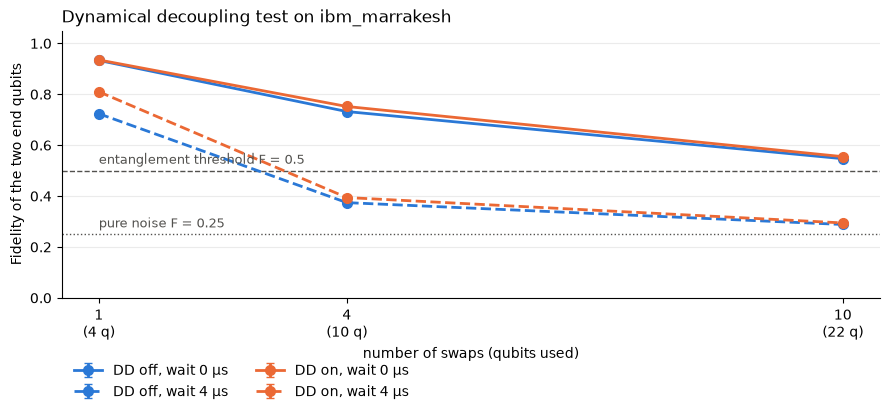

In [18]:
def plot_dd(off, on, title):
    fig, ax = plt.subplots(figsize=(9, 4.4))
    styles = {DD_WAITS_NS[0]: "-", **{w: "--" for w in DD_WAITS_NS[1:]}}
    for summ, color, dd_name in [(off, COLOR_CHAIN, "DD off"), (on, COLOR_CONTROL, "DD on")]:
        for w in DD_WAITS_NS:
            F = [summ[f"wait{w}"][n]["All, corrected"]["F"] for n in DD_N_SWAPS]
            E = [summ[f"wait{w}"][n]["All, corrected"]["err"] for n in DD_N_SWAPS]
            ax.errorbar(DD_N_SWAPS, F, yerr=E, color=color, linestyle=styles[w], marker="o", markersize=7,
                        linewidth=2, capsize=3, label=f"{dd_name}, wait {w / 1000:g} µs")
    ax.axhline(0.5, color=INK, linestyle="--", linewidth=1)
    ax.text(min(DD_N_SWAPS), 0.515, "entanglement threshold F = 0.5", ha="left", va="bottom", color=INK, fontsize=9)
    ax.axhline(0.25, color=INK, linestyle=":", linewidth=1)
    ax.text(min(DD_N_SWAPS), 0.265, "pure noise F = 0.25", ha="left", va="bottom", color=INK, fontsize=9)
    ax.set_xticks(DD_N_SWAPS, [f"{k}\n({2 * k + 2} q)" for k in DD_N_SWAPS])
    ax.set_xlabel("number of swaps (qubits used)")
    ax.set_ylabel("Fidelity of the two end qubits")
    ax.set_ylim(0, 1.05)
    ax.set_title(title, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2)
    fig.tight_layout()
    return fig


fig = plot_dd(dd_off, dd_on, f"Dynamical decoupling test on {backend.name}")
fig.savefig(RESULTS_DIR / f"{dd_stamp}_{backend.name}_dd_fidelity.png", dpi=150)

In [19]:
dd_record = {
    "experiment": "entanglement_swapping_chain_dd_test",
    "timestamp_utc": dd_stamp,
    "backend": backend.name,
    "job_ids": DD_JOB_IDS,
    "shots_per_circuit": DD_SHOTS,
    "n_swaps": DD_N_SWAPS,
    "waits_ns": DD_WAITS_NS,
    "dd_sequence": "X-X per idle gap (PadDynamicalDecoupling, ALAP)",
    "physical_qubit_line": LINE,
    "dd_pulses": {on.name: n_x(on) - n_x(off) for off, on in zip(dd_isa_off, dd_isa_on)} if "dd_isa_on" in globals() else None,
    "summary": {
        dd_name: {wk: {str(n): s for n, s in by_n.items()} for wk, by_n in summ.items()}
        for dd_name, summ in (("off", dd_off), ("on", dd_on))
    },
    "counts": {
        dd_name: {wk: {str(n): c for n, c in by_n.items()} for wk, by_n in cnt.items()}
        for dd_name, cnt in (("off", dd_off_counts), ("on", dd_on_counts))
    },
}
path = RESULTS_DIR / f"{dd_stamp}_{backend.name}_dd_results.json"
path.write_text(json.dumps(dd_record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", path)

print("\nLog lines for CLAUDE.md:")
for w in DD_WAITS_NS:
    for n in DD_N_SWAPS:
        a = dd_off[f"wait{w}"][n]["All, corrected"]
        b = dd_on[f"wait{w}"][n]["All, corrected"]
        print(f"| {dd_stamp} | {backend.name} | {DD_JOB_IDS['off']} / {DD_JOB_IDS['on']} | DD test, {n} swaps, "
              f"wait {w / 1000:g} µs | {DD_SHOTS} | off {a['F']:.3f} ± {a['err']:.3f} / on {b['F']:.3f} ± {b['err']:.3f} | - | |")

Saved results\20261016T053914Z_ibm_marrakesh_dd_results.json

Log lines for CLAUDE.md:
| 20261016T053914Z | ibm_marrakesh | db8rh0dckpjs73b1ilr0 / db8rh0m94fic73etvka0 | DD test, 1 swaps, wait 0 µs | 4000 | off 0.933 ± 0.003 / on 0.935 ± 0.003 | - | |
| 20261016T053914Z | ibm_marrakesh | db8rh0dckpjs73b1ilr0 / db8rh0m94fic73etvka0 | DD test, 4 swaps, wait 0 µs | 4000 | off 0.732 ± 0.005 / on 0.752 ± 0.005 | - | |
| 20261016T053914Z | ibm_marrakesh | db8rh0dckpjs73b1ilr0 / db8rh0m94fic73etvka0 | DD test, 10 swaps, wait 0 µs | 4000 | off 0.547 ± 0.006 / on 0.555 ± 0.006 | - | |
| 20261016T053914Z | ibm_marrakesh | db8rh0dckpjs73b1ilr0 / db8rh0m94fic73etvka0 | DD test, 1 swaps, wait 4 µs | 4000 | off 0.724 ± 0.005 / on 0.810 ± 0.005 | - | |
| 20261016T053914Z | ibm_marrakesh | db8rh0dckpjs73b1ilr0 / db8rh0m94fic73etvka0 | DD test, 4 swaps, wait 4 µs | 4000 | off 0.374 ± 0.007 / on 0.394 ± 0.007 | - | |
| 20261016T053914Z | ibm_marrakesh | db8rh0dckpjs73b1ilr0 / db8rh0m94fic73etvka0 | DD t

### How to read the DD test
- **Wait 0 µs, DD off vs on:** expected to be the same within ~2 SE. Your chain is limited by readout and
  gate errors, which DD cannot fix.
- **Wait 4 µs, DD off:** the stored Bell pairs dephase, so XX and YY fade and F drops. The longer the chain,
  the more qubits are waiting, so the drop is biggest for 10 swaps.
- **Wait 4 µs, DD on:** if DD works, it should recover much of that loss. It cannot recover all of it: a
  single X–X pair only cancels slow drifts, and genuine decoherence (T1, T2) still happens.

## Interpreting the results

- **F above 0.5** for a chain length: the two end qubits are proven entangled across the whole chain.
- **F falling with each extra swap**: every added Bell pair and Bell measurement brings more gate and
  readout errors, and a single wrong Bell-measurement bit gives the shot the wrong correction.
- **The fitted r** is the fraction of "entanglement quality" that survives each extra swap. The
  predicted longest chain is where the fit crosses F = 0.5.
- **Controls near 0.25** at every length: without the Bell measurements nothing links the two ends.

Real quantum repeaters fight this decay with *entanglement distillation* (purification) and quantum
memories; on today's hardware the simplest improvements are error suppression (dynamical decoupling,
twirling) and choosing the qubit line with the lowest readout error.